## Usando Keras para Construir e Treinar Redes Neurais

Neste exercício usaremos uma rede neural para prever diabetes usando o Dataset de Diabetes Pima. Começaremos treinando uma Random Forest para obter uma linha de base de desempenho. Em seguida, usaremos o pacote Keras para construir e treinar rapidamente uma rede neural e comparar o desempenho. Veremos como diferentes estruturas de rede afetam o desempenho, o tempo de treinamento e o nível de overfitting (ou underfitting).

## Dataset de Diabetes Pima da UCI

* Repositório ML da UCI (http://archive.ics.uci.edu/ml/datasets/Pima+Indians+Diabetes)


### Atributos: (todos com valores numéricos)
   1. Número de vezes grávida
   2. Concentração de glicose plasmática 2 horas após teste oral de tolerância à glicose
   3. Pressão arterial diastólica (mm Hg)
   4. Espessura da dobra cutânea do tríceps (mm)
   5. Insulina sérica de 2 horas (mu U/ml)
   6. Índice de massa corporal (peso em kg/(altura em m)^2)
   7. Função de pedigree da diabetes
   8. Idade (anos)
   9. Variável de classe (0 ou 1)

O Dataset de Diabetes Pima da UCI que possui 8 preditores numéricos e um resultado binário.

In [16]:
#Preliminares

from __future__ import absolute_import, division, print_function  # Python 2/3 compatibility

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve, accuracy_score
from sklearn.ensemble import RandomForestClassifier

import seaborn as sns

%matplotlib inline

In [17]:
## Importar objetos do Keras para Deep Learning

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam, SGD, RMSprop

In [18]:
"""SÓ RODA ISSO SE FOR NO COLAB E COM GPU"""

import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
  try:
    # Ativa o crescimento de memória para todas as GPUs visíveis
    for gpu in gpus:
      tf.config.experimental.set_memory_growth(gpu, True)
    logical_gpus = tf.config.list_logical_devices('GPU')
    print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
  except RuntimeError as e:
    print(e)


1 Physical GPUs, 1 Logical GPUs


In [19]:
## Carregar o conjunto de dados (Acesso à Internet necessário)

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/refs/heads/master/diabetes.csv"
names = ["times_pregnant", "glucose_tolerance_test", "blood_pressure", "skin_thickness", "insulin",
         "bmi", "pedigree_function", "age", "has_diabetes"]
diabetes_df = pd.read_csv(url)
diabetes_df.columns = names

In [20]:
# Dar uma olhada nos dados -- se houver muitos "NaN" você pode ter problemas de conectividade com a internet
print(diabetes_df.shape)
diabetes_df.sample(5)

(768, 9)


,times_pregnant,glucose_tolerance_test,blood_pressure,skin_thickness,insulin,bmi,pedigree_function,age,has_diabetes
485,0,135,68,42,250,42.3,0.365,24,1
565,2,95,54,14,88,26.1,0.748,22,0
78,0,131,0,0,0,43.2,0.270,26,1
459,9,134,74,33,60,25.9,0.460,81,0
446,1,100,72,12,70,25.3,0.658,28,0


In [21]:
X = diabetes_df.iloc[:, :-1].values
y = diabetes_df["has_diabetes"].values


In [22]:
# Dividir os dados em Treinamento e Teste (75%, 25%)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=13221470)

In [23]:
np.mean(y), np.mean(1-y)

(np.float64(0.3489583333333333), np.float64(0.6510416666666666))

Acima, vemos que cerca de 35% dos pacientes neste dataset têm diabetes, enquanto 65% não têm. Isso significa que podemos obter uma precisão de 65% sem nenhum modelo - apenas declarando que ninguém tem diabetes. Calcularemos a pontuação ROC-AUC para avaliar o desempenho do nosso modelo, e também observaremos a precisão para ver se melhoramos a precisão de 65%.
## Exercício: Obtenha um desempenho de linha de base usando Random Forest
Para começar e obter uma linha de base para o desempenho do classificador:
1. Treine um modelo Random Forest com 200 árvores nos dados de treinamento.
2. Calcule a precisão e o roc_auc_score das predições.

In [24]:
## Treinar o Modelo RF
rf_model = RandomForestClassifier(n_estimators=200)
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200)

In [25]:
# Fazer previsões no conjunto de teste - tanto previsões "definitivas" quanto os scores (porcentagem de árvores votando sim)
y_pred_class_rf = rf_model.predict(X_test)
y_pred_prob_rf = rf_model.predict_proba(X_test)


print('accuracy is {:.3f}'.format(accuracy_score(y_test,y_pred_class_rf)))
print('roc-auc is {:.3f}'.format(roc_auc_score(y_test,y_pred_prob_rf[:,1])))

accuracy is 0.792
roc-auc is 0.848


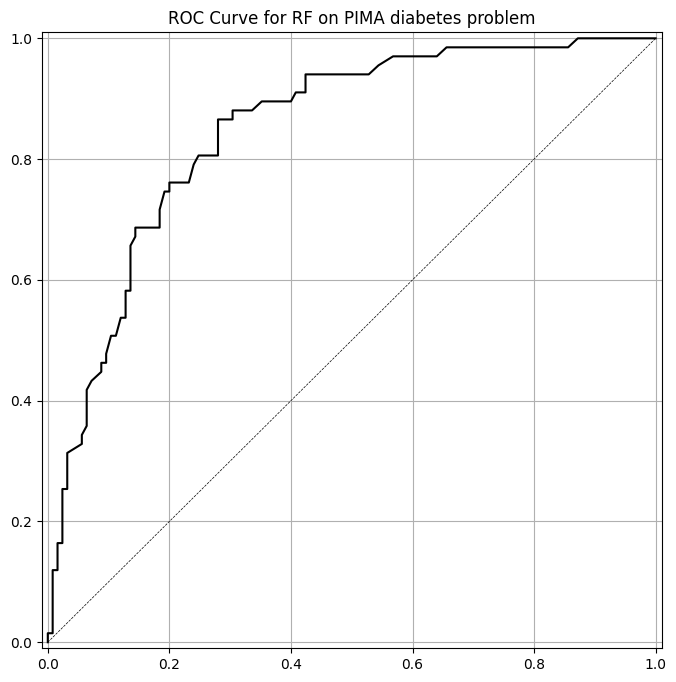

In [26]:
def plot_roc(y_test, y_pred, model_name):
    fpr, tpr, thr = roc_curve(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.plot(fpr, tpr, 'k-')
    ax.plot([0, 1], [0, 1], 'k--', linewidth=.5)  # roc curve for random model
    ax.grid(True)
    ax.set(title='ROC Curve for {} on PIMA diabetes problem'.format(model_name),
           xlim=[-0.01, 1.01], ylim=[-0.01, 1.01])


plot_roc(y_test, y_pred_prob_rf[:, 1], 'RF')

## Construir uma Rede Neural de Camada Oculta Única

Usaremos o modelo Sequential para construir rapidamente uma rede neural. Nossa primeira rede será uma rede de camada única. Temos 8 variáveis, então definimos o formato de entrada como 8. Vamos começar tendo uma única camada oculta com 12 nós.

In [27]:
## Primeiro vamos normalizar os dados
## Isso auxilia o treinamento de redes neurais fornecendo estabilidade numérica
## Random Forest não precisa disso pois encontra apenas uma divisão, ao contrário de realizar multiplicações de matrizes


normalizer = StandardScaler()
X_train_norm = normalizer.fit_transform(X_train)
X_test_norm = normalizer.transform(X_test)

In [28]:
# Definir o Modelo
# Tamanho de entrada é 8-dimensional
# 1 camada oculta, 12 nós ocultos, ativação sigmoid
# Camada final tem apenas um nó com ativação sigmoid (padrão para classificação binária)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model_1 = Sequential([
    Dense(12, input_shape=(8,), activation="relu"),
    Dense(1, activation="sigmoid")
])

In [29]:
# Esta é uma ferramenta útil para visualizar o modelo que você criou e contar os parâmetros

model_1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 12)             │           108 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121 (484.00 B)

 Trainable params: 121 (484.00 B)

 Non-trainable params: 0 (0.00 B)

### Pergunta de compreensão:
Por que temos 121 parâmetros? Isso faz sentido?

### Resposta:

1 - para a camada oculta, teremos 12 neuronios, cada um com 8 pesos e 1 bias, logo, 12x9 = 108
2 - para a camada de saída, será so um neurônio com 12 entradas, logo, 12 pesos e 1 bias = 13

108 + 13 = 121

Vamos ajustar nosso modelo por 200 épocas.

In [30]:
# Ajustar(Treinar) o Modelo

# Compilar o modelo com Otimizador, Função de Perda e Métricas
# Roc-Auc ainda não está disponível no Keras como uma métrica pronta para uso, então vamos pular isso aqui.

model_1.compile(SGD(learning_rate = .005), "binary_crossentropy", metrics=["accuracy"], jit_compile=True)
run_hist_1 = model_1.fit(X_train_norm, y_train, validation_data=(X_test_norm, y_test), epochs=200, batch_size=32)
# a função fit retorna o histórico de execução.
# É muito conveniente, pois contém informações sobre o ajuste do modelo, iterações etc.

Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.6441 - loss: 0.6386 - val_accuracy: 0.6667 - val_loss: 0.6487
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6493 - loss: 0.6343 - val_accuracy: 0.6667 - val_loss: 0.6450
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.6580 - loss: 0.6304 - val_accuracy: 0.6719 - val_loss: 0.6414
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6562 - loss: 0.6266 - val_accuracy: 0.6771 - val_loss: 0.6379
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6632 - loss: 0.6230 - val_accuracy: 0.6823 - val_loss: 0.6346
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6615 - loss: 0.6194 - val_accuracy: 0.6719 - val_loss: 0.6313
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6649 - loss: 0.6160 - val_accuracy: 0.6771 - val_loss: 0.6283
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6632 - loss: 0.6127 - val_accuracy: 0.6823 

In [31]:
## Como fizemos para o Random Forest, geramos dois tipos de previsões
# Uma é uma decisão definitiva, a outra é um score probabilístico.

y_pred_prob_nn_1 = model_1.predict(X_test_norm)
y_pred_class_nn_1 = (y_pred_prob_nn_1 > 0.5).astype("int32")


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step  


In [32]:
# Vamos verificar as saídas para ter uma noção de como as APIs do keras funcionam.
y_pred_class_nn_1[:10]

array([[1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1]], dtype=int32)

In [33]:
y_pred_prob_nn_1[:10]

array([[0.59858257],
       [0.7686192 ],
       [0.46190912],
       [0.66733444],
       [0.2509159 ],
       [0.798895  ],
       [0.05855584],
       [0.7321235 ],
       [0.64928895],
       [0.62585825]], dtype=float32)

accuracy is 0.776
roc-auc is 0.836


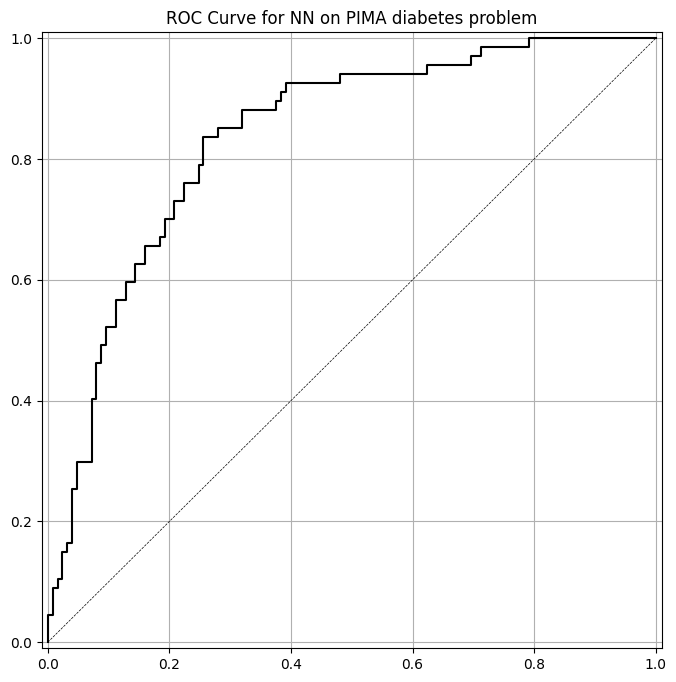

In [34]:
# Imprimir performance do modelo e plotar a curva roc
print('accuracy is {:.3f}'.format(accuracy_score(y_test,y_pred_class_nn_1)))
print('roc-auc is {:.3f}'.format(roc_auc_score(y_test,y_pred_prob_nn_1)))

plot_roc(y_test, y_pred_prob_nn_1, 'NN')

Pode haver alguma variação nos números exatos devido à aleatoriedade, mas você deve obter resultados na mesma faixa da Random Forest - entre 75% e 85% de precisão, entre 0,8 e 0,9 para AUC.

Vamos observar o objeto `run_hist_1` que foi criado, especificamente seu atributo `history`.

In [35]:
run_hist_1.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

Vamos plotar a perda de treinamento e a perda de validação ao longo das diferentes épocas e ver como fica.

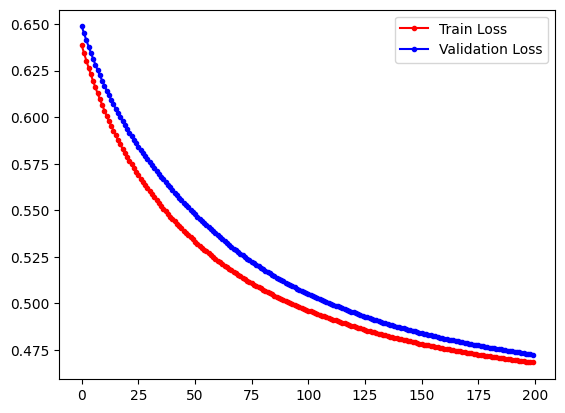

In [36]:
fig, ax = plt.subplots()
ax.plot(run_hist_1.history["loss"],'r', marker='.', label="Train Loss")
ax.plot(run_hist_1.history["val_loss"],'b', marker='.', label="Validation Loss")
ax.legend()

Parece que as perdas ainda estão diminuindo tanto no conjunto de treinamento quanto no conjunto de validação. Isso sugere que o modelo pode se beneficiar de mais treinamento. Vamos treinar o modelo um pouco mais e ver o que acontece. Observe que ele continuará de onde parou. Treine por mais 1000 épocas.

In [37]:
## Note que quando chamamos "fit" novamente, ele continua de onde parou
run_hist_1b = model_1.fit(X_train_norm, y_train, validation_data=(X_test_norm, y_test), epochs=1000)

Epoch 1/1000
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7812 - loss: 0.4682 - val_accuracy: 0.7760 - val_loss: 0.4724
Epoch 2/1000
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7812 - loss: 0.4680 - val_accuracy: 0.7760 - val_loss: 0.4722
Epoch 3/1000
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7830 - loss: 0.4679 - val_accuracy: 0.7760 - val_loss: 0.4720
Epoch 4/1000
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7830 - loss: 0.4677 - val_accuracy: 0.7760 - val_loss: 0.4718
Epoch 5/1000
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7812 - loss: 0.4676 - val_accuracy: 0.7760 - val_loss: 0.4717
Epoch 6/1000
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7830 - loss: 0.4674 - val_accuracy: 0.7760 - val_loss: 0.4715
Epoch 7/1000
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7847 - loss: 0.4673 - val_accuracy: 0.7760 - val_loss: 0.4713
Epoch 8/1000
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7830 - loss: 0.4671 - val_accuracy: 0.

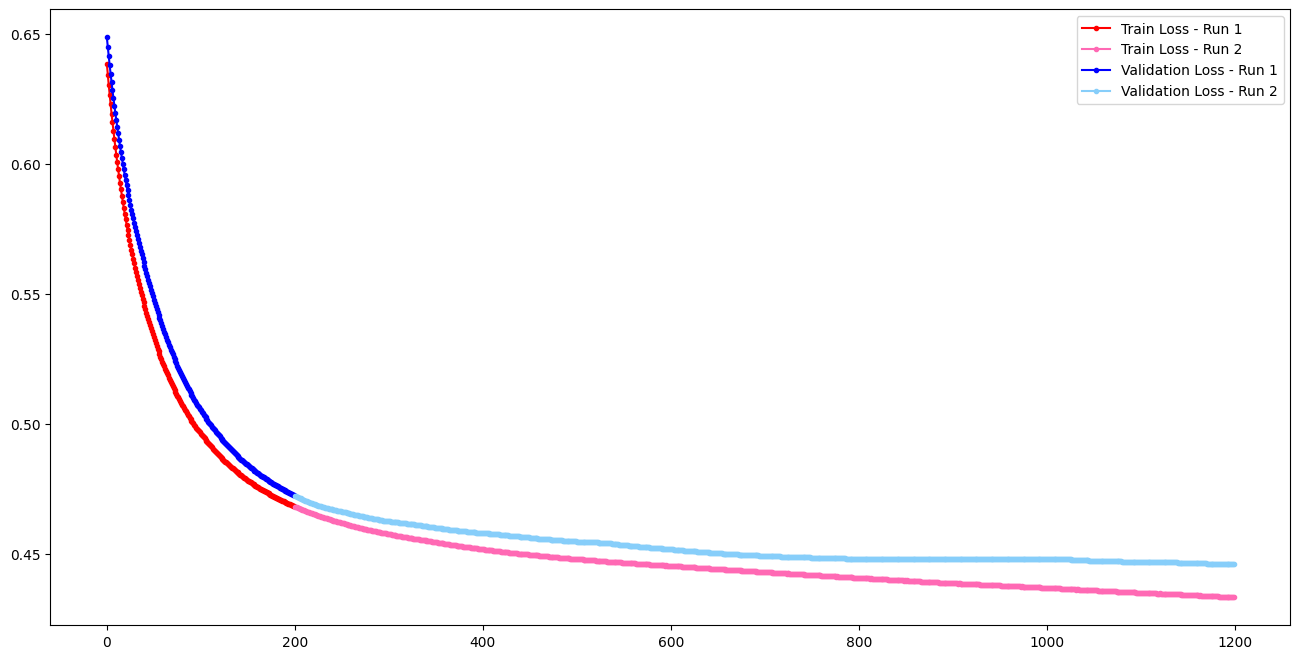

In [38]:
n = len(run_hist_1.history["loss"])
m = len(run_hist_1b.history['loss'])
fig, ax = plt.subplots(figsize=(16, 8))

ax.plot(range(n), run_hist_1.history["loss"],'r', marker='.', label="Train Loss - Run 1")
ax.plot(range(n, n+m), run_hist_1b.history["loss"], 'hotpink', marker='.', label="Train Loss - Run 2")

ax.plot(range(n), run_hist_1.history["val_loss"],'b', marker='.', label="Validation Loss - Run 1")
ax.plot(range(n, n+m), run_hist_1b.history["val_loss"], 'LightSkyBlue', marker='.',  label="Validation Loss - Run 2")

ax.legend()

Observe que este gráfico começa onde o outro parou. Embora a perda de treinamento ainda esteja diminuindo, parece que a perda de validação se estabilizou (ou até piorou!). Isso sugere que nossa rede não se beneficiará de mais treinamento. Qual é o número apropriado de épocas?

Por volta da época 800-900, a linha do validation-loss e do train-loss começam a se distanciar muito, além do validation-loss se estabilizar e dar uma subida leve depois, sendo sinal claro de que o modelo já se estabilizou e pode acabar gerando overfitting caso tenha mais épocas.

## Exercício
Agora é sua vez. Faça o seguinte nas células abaixo:
- Construa um modelo com duas camadas ocultas, cada uma com 6 nós
- Use a função de ativação "relu" para as camadas ocultas, e "sigmoid" para a camada final
- Use uma taxa de aprendizado de 0,003 e treine por 1500 épocas
- Faça um gráfico da trajetória das funções de perda, precisão tanto no conjunto de treino quanto no de teste
- Plote a curva ROC para as predições

Experimente com diferentes taxas de aprendizado, números de épocas e estruturas de rede

In [46]:
# Digite seu código aqui com as camadas 1,2 tendo ativação relu e camada 3 com ativação sigmoid

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model2 = Sequential([
    Dense(6, input_shape=(8, ), activation='relu'),
    Dense(6, input_shape=(6, ), activation='relu'),
    Dense(1, activation='sigmoid')
])

model2.summary()

model2.compile(SGD(learning_rate = .003), "binary_crossentropy", metrics=["accuracy"], jit_compile=True)
historico = model2.fit(X_train_norm, y_train, validation_data=(X_test_norm, y_test), epochs=1500)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 6)              │            54 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 6)              │            42 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 103 (412.00 B)

 Trainable params: 103 (412.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/1500
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.4653 - loss: 0.7185 - val_accuracy: 0.4948 - val_loss: 0.7111
Epoch 2/1500
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4792 - loss: 0.7088 - val_accuracy: 0.5260 - val_loss: 0.7011
Epoch 3/1500
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5035 - loss: 0.7000 - val_accuracy: 0.5677 - val_loss: 0.6918
Epoch 4/1500
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5365 - loss: 0.6918 - val_accuracy: 0.6094 - val_loss: 0.6833
Epoch 5/1500
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5903 - loss: 0.6844 - val_accuracy: 0.6042 - val_loss: 0.6757
Epoch 6/1500
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6163 - loss: 0.6777 - val_accuracy: 0.6094 - val_loss: 0.6686
Epoch 7/1500
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6215 - loss: 0.6714 - val_accuracy: 0.6146 - val_loss: 0.6620
Epoch 8/1500
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6267 - loss: 0.6656 - val_accur

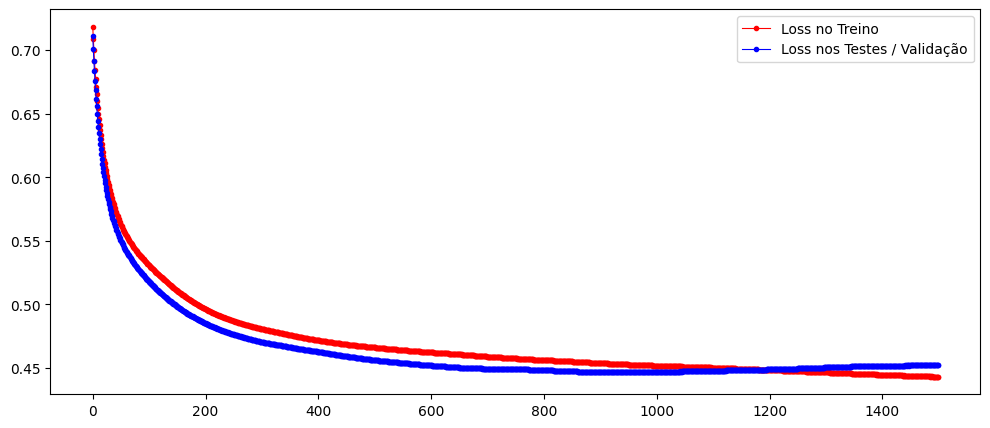

In [49]:
# Digite seu código aqui para plotar a perda, acurácia e curva ROC

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(historico.history["loss"],'r', marker='.', label="Loss no Treino", linewidth=0.8)
ax.plot(historico.history["val_loss"],'b', marker='.', label="Loss nos Testes / Validação", linewidth=0.8)
ax.legend()

In [54]:
from sklearn.metrics import roc_auc_score, accuracy_score

y_prob = model2.predict(X_test_norm)
y_prev = (y_prob > 0.5).astype("int32")

print(f'Acurácia : {accuracy_score(y_test, y_prev)}')
print(f'ROC AUC : {roc_auc_score(y_test, y_prob)}')


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step 
Acurácia : 0.7916666666666666
ROC AUC : 0.8496716417910448


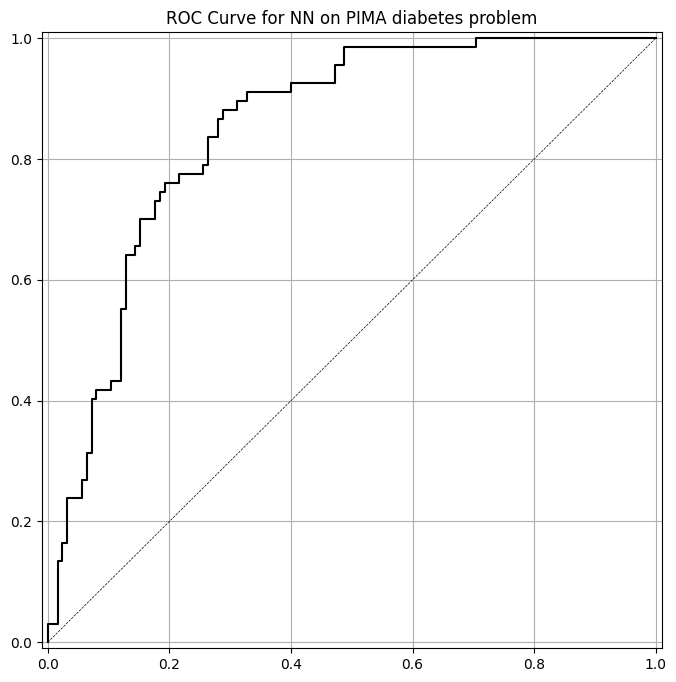

In [55]:
plot_roc(y_test, y_prob, 'NN')